In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
data=pd.read_csv("us_retail_sales_2020_2025.csv")
data

,naics_code,kind_of_business,sales_month,sales,estimate_type
0,NaN,Retail sales and food services excl gasoline s...,2020-01-01,482009.0,adjusted
1,NaN,Retail sales and food services excl motor vehi...,2020-01-01,379692.0,adjusted
2,442443,"Furniture, home furn, electronics, and applian...",2020-01-01,17834.0,adjusted
3,4413,"Automotive parts, acc., and tire stores",2020-01-01,7990.0,adjusted
4,NaN,"Retail sales, total (excl. motor vehicle and p...",2020-01-01,354103.0,adjusted
...,...,...,...,...,...
5866,44811,Men's clothing stores,2024-09-01,NaN,not adjusted
5867,4481,Clothing stores,2024-09-01,16569.0,not adjusted
5868,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
5869,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [2]:
data.columns = (data.columns.str.strip().str.title())
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,NaN,Retail sales and food services excl gasoline s...,2020-01-01,482009.0,adjusted
1,NaN,Retail sales and food services excl motor vehi...,2020-01-01,379692.0,adjusted
2,442443,"Furniture, home furn, electronics, and applian...",2020-01-01,17834.0,adjusted
3,4413,"Automotive parts, acc., and tire stores",2020-01-01,7990.0,adjusted
4,NaN,"Retail sales, total (excl. motor vehicle and p...",2020-01-01,354103.0,adjusted
...,...,...,...,...,...
5866,44811,Men's clothing stores,2024-09-01,NaN,not adjusted
5867,4481,Clothing stores,2024-09-01,16569.0,not adjusted
5868,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
5869,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [3]:
display(data.isna().sum())

Naics_Code          798
Kind_Of_Business      0
Sales_Month           0
Sales               438
Estimate_Type         0
dtype: int64

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5871 entries, 0 to 5870
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Naics_Code        5073 non-null   str    
 1   Kind_Of_Business  5871 non-null   str    
 2   Sales_Month       5871 non-null   str    
 3   Sales             5433 non-null   float64
 4   Estimate_Type     5871 non-null   str    
dtypes: float64(1), str(4)
memory usage: 229.5 KB


In [5]:
print(data["Naics_Code"].unique())

<StringArray>
[                     nan,                 '442443',                   '4413',
                    '441',               '44114412',                   '7224',
 '722513, 722514, 722515',                 '722511',                   '7225',
                    '722',                  '45431',                   '4541',
                    '454',                  '45330',                    '442',
                  '45322',                  '45321',                    '443',
                  '44831',                   '4441',                   '4532',
                    '453',                  '45299',                  '45291',
                   '4529',                   '4521',                    '452',
                    '451',                   '4482',                  '44812',
                  '44811',                   '4481',                    '448',
                    '447',                  '44611',                    '446',
                   '4453',            

In [6]:
data = data.dropna(subset=["Naics_Code"])

In [7]:
data = data.dropna(subset=["Sales"])

In [8]:
data=data.reset_index(drop=True)
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,442443,"Furniture, home furn, electronics, and applian...",2020-01-01,17834.0,adjusted
1,4413,"Automotive parts, acc., and tire stores",2020-01-01,7990.0,adjusted
2,441,Motor vehicle and parts dealers,2020-01-01,102317.0,adjusted
3,44114412,Automobile and other motor vehicle dealers,2020-01-01,94327.0,adjusted
4,"722513, 722514, 722515",Limited service eating places,2020-01-01,27239.0,not adjusted
...,...,...,...,...,...
4630,44812,Women's clothing stores,2024-09-01,2673.0,not adjusted
4631,4481,Clothing stores,2024-09-01,16569.0,not adjusted
4632,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
4633,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [9]:
data=data[data["Naics_Code"]!= 447 ]
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,442443,"Furniture, home furn, electronics, and applian...",2020-01-01,17834.0,adjusted
1,4413,"Automotive parts, acc., and tire stores",2020-01-01,7990.0,adjusted
2,441,Motor vehicle and parts dealers,2020-01-01,102317.0,adjusted
3,44114412,Automobile and other motor vehicle dealers,2020-01-01,94327.0,adjusted
4,"722513, 722514, 722515",Limited service eating places,2020-01-01,27239.0,not adjusted
...,...,...,...,...,...
4630,44812,Women's clothing stores,2024-09-01,2673.0,not adjusted
4631,4481,Clothing stores,2024-09-01,16569.0,not adjusted
4632,448,Clothing and clothing access. stores,2024-09-01,23142.0,not adjusted
4633,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not adjusted


In [10]:
print(data["Naics_Code"].unique())

<StringArray>
[                '442443',                   '4413',                    '441',
               '44114412', '722513, 722514, 722515',                 '722511',
                   '7225',                    '722',                  '45431',
                   '4541',                    '454',                  '45330',
                    '442',                  '45322',                  '45321',
                    '443',                  '44831',                   '4441',
                   '4532',                    '453',                  '45299',
                  '45291',                   '4529',                   '4521',
                    '452',                    '451',                   '4482',
                  '44812',                  '44811',                   '4481',
                    '448',                    '447',                  '44611',
                    '446',                   '4453',                   '4451',
                    '445',            

In [11]:
data['Estimate_Type']=data['Estimate_Type'].replace('not adjusted','not_adjusted')
data

,Naics_Code,Kind_Of_Business,Sales_Month,Sales,Estimate_Type
0,442443,"Furniture, home furn, electronics, and applian...",2020-01-01,17834.0,adjusted
1,4413,"Automotive parts, acc., and tire stores",2020-01-01,7990.0,adjusted
2,441,Motor vehicle and parts dealers,2020-01-01,102317.0,adjusted
3,44114412,Automobile and other motor vehicle dealers,2020-01-01,94327.0,adjusted
4,"722513, 722514, 722515",Limited service eating places,2020-01-01,27239.0,not_adjusted
...,...,...,...,...,...
4630,44812,Women's clothing stores,2024-09-01,2673.0,not_adjusted
4631,4481,Clothing stores,2024-09-01,16569.0,not_adjusted
4632,448,Clothing and clothing access. stores,2024-09-01,23142.0,not_adjusted
4633,"722513, 722514, 722515",Limited service eating places,2024-09-01,41681.0,not_adjusted


In [12]:
import plotly.express as px
# 1. Group by month and sum the sales across all categories
df_trend = (
    data[data["Estimate_Type"] == "adjusted"]
    .dropna(subset=["Sales"])
    .groupby("Sales_Month", as_index=False)["Sales"]
    .sum()
)

# 2. Create the trend line
fig = px.line(
    df_trend,
    x="Sales_Month",
    y="Sales",
    title="Total US Retail Sales Trend Over Time (All Categories Combined)",
    labels={"Sales_Month": "Date", "Sales": "Total Sales ($ Millions)"},
    template="plotly_white",
)

fig.update_layout(hovermode="x unified")
fig.show()

In [13]:

# Convert Sales_Month to datetime to easily extract Year and Month
df_trend["Sales_Month"] = pd.to_datetime(df_trend["Sales_Month"])
df_trend["Year"] = df_trend["Sales_Month"].dt.year
df_trend["Month"] = df_trend["Sales_Month"].dt.month

# 3. Calculate Annual Total Sales per year
annual_totals = (
    df_trend.groupby("Year")["Sales"]
    .sum()
    .reset_index()
    .rename(columns={"Sales": "Annual_Total"})
)

# 4. Calculate Nov (Month 11) + Dec (Month 12) total sales per year
nov_dec_df = df_trend[df_trend["Month"].isin([11, 12])]
nov_dec_totals = (
    nov_dec_df.groupby("Year")["Sales"]
    .sum()
    .reset_index()
    .rename(columns={"Sales": "Nov_Dec_Total"})
)

# 5. Merge and compute percentage share
df_share = pd.merge(nov_dec_totals, annual_totals, on="Year")
df_share["Share_Pct"] = (df_share["Nov_Dec_Total"] / df_share["Annual_Total"]) * 100
df_share["Share_Text"] = df_share["Share_Pct"].round(1).astype(str) + "%"

# Filter for years 2020 to 2023 (or whatever full years are available)
df_share = df_share[
    (df_share["Year"] >= 2020) & (df_share["Year"] <= 2024)
]

# 6. Create the Bar Chart using Plotly Graph Objects for precise annotation control
fig = go.Figure()

# Add the main bars
fig.add_trace(
    go.Bar(
        x=df_share["Year"].astype(str),
        y=df_share["Share_Pct"],
        text=df_share["Share_Text"],
        textposition="outside",
        marker_color="#b86b35",  # Warm brownish-orange color matching your screenshot
        width=0.6,
    )
)

# Add horizontal dashed line for "even spread" (16.7% since 2 months out of 12 = 16.67%)
even_spread = (2 / 12) * 100
fig.add_shape(
    type="line",
    x0=-0.5,
    x1=len(df_share) - 0.5,
    y0=even_spread,
    y1=even_spread,
    line=dict(color="rgba(80, 110, 140, 0.8)", width=2, dash="dash"),
)

# Add annotation for the even spread line
fig.add_annotation(
    x=3.8,
    y=even_spread,
    text=f"even spread ({even_spread:.1f}%)",
    showarrow=False,
    yshift=2,
    font=dict(color="rgba(80, 110, 140, 0.9)", size=12),
)

# 7. Layout styling matching the clean look of the screenshot
fig.update_layout(
    title=dict(
        text="<b>Nov + Dec share of annual total retail sales</b>",
        font=dict(size=18, color="black"),
    ),
    xaxis=dict(title="", tickfont=dict(size=14)),
    yaxis=dict(
        title="",
        range=[0, 22],
        tickformat=".0f",
        ticksuffix="%",
        dtick=3,
        showgrid=True,
        gridcolor="rgba(210, 215, 220, 0.5)",
    ),
    plot_bgcolor="white",
    paper_bgcolor="white",
    showlegend=False,
    margin=dict(t=60, b=40, l=40, r=40),
)

fig.show()

In [14]:
# 3. Classify months into groups: "Nov-Dec" vs "Jan-Oct"
df_trend["Period_Group"] = df_trend["Month"].apply(
    lambda m: "Nov-Dec" if m in [11, 12] else "Jan-Oct"
)

# 4. Aggregate sales by Year and Period_Group
df_grouped = (
    df_trend.groupby(["Year", "Period_Group"])["Sales"]
    .sum()
    .reset_index()
)

# 5. Calculate YoY Growth (%) relative to the previous year for each group
df_grouped["Prior_Sales"] = df_grouped.groupby("Period_Group")["Sales"].shift(1)
df_grouped["YoY_Growth"] = (
    (df_grouped["Sales"] - df_grouped["Prior_Sales"]) / df_grouped["Prior_Sales"]
) * 100

# Format text labels with percentage sign
df_grouped["Growth_Text"] = df_grouped["YoY_Growth"].round(1).astype(str) + "%"

# Filter for years 2021 to 2023 (since 2020 is needed as base year for YoY calculation)
df_filtered = df_grouped[
    (df_grouped["Year"] >= 2021) & (df_grouped["Year"] <= 2023)
]

# 6. Create the Grouped Bar Chart using Plotly Graph Objects
fig = go.Figure()

# Colors matching the image: Brown/Orange for Nov-Dec, Blue for Jan-Oct
colors = {"Nov-Dec": "#b86b35", "Jan-Oct": "#2b5c8f"}

for period in ["Nov-Dec", "Jan-Oct"]:
    df_subset = df_filtered[df_filtered["Period_Group"] == period]
    fig.add_trace(
        go.Bar(
            x=df_subset["Year"].astype(str),
            y=df_subset["YoY_Growth"],
            name=period,
            text=df_subset["Growth_Text"],
            textposition="outside",
            marker_color=colors[period],
            width=0.35,
        )
    )

# 7. Layout styling
fig.update_layout(
    title=dict(
        text="<b>Holiday season vs. rest-of-year growth</b>",
        font=dict(size=18, color="black"),
    ),
    xaxis=dict(title="year", tickfont=dict(size=14)),
    yaxis=dict(
        title="YoY growth (%)",
        range=[0, 21],
        tickformat=".1f",
        ticksuffix="%",
        dtick=2.5,
        showgrid=True,
        gridcolor="rgba(210, 215, 220, 0.5)",
    ),
    barmode="group",
    plot_bgcolor="white",
    paper_bgcolor="white",
    legend=dict(
        x=0.78,
        y=0.95,
        bgcolor="rgba(255,255,255,0.8)",
        bordercolor="rgba(200,200,200,0.5)",
        borderwidth=1,
    ),
    margin=dict(t=60, b=40, l=50, r=40),
)

fig.show()

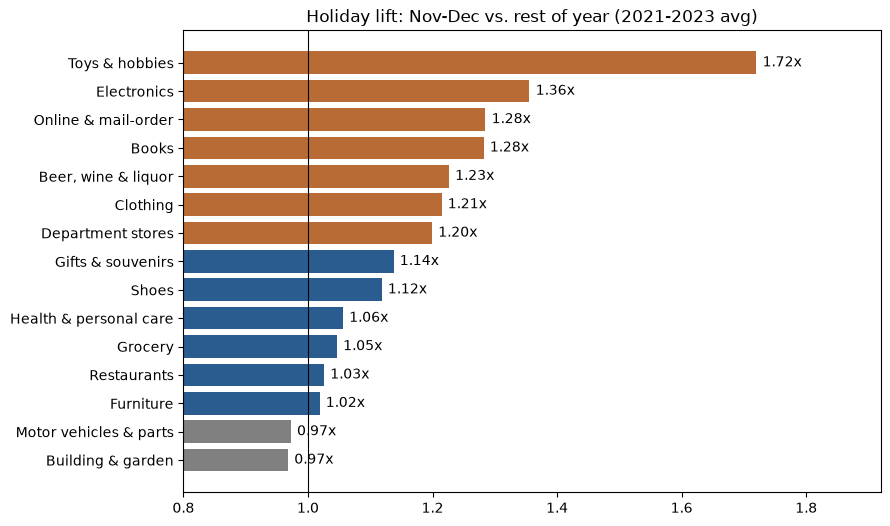

In [16]:
import matplotlib.pyplot as plt
cats = {
    "Hobby, toy, and game stores": "Toys & hobbies",
    "Book stores": "Books",
    "Department stores": "Department stores",
    "Electronics stores": "Electronics",
    "Clothing stores": "Clothing",
    "Shoe stores": "Shoes",
    "Gift, novelty, and souvenir stores": "Gifts & souvenirs",
    "Electronic shopping and mail-order houses": "Online & mail-order",
    "Beer, wine, and liquor stores": "Beer, wine & liquor",
    "Furniture stores": "Furniture",
    "Grocery stores": "Grocery",
    "Health and personal care stores": "Health & personal care",
    "Restaurants and other eating places": "Restaurants",
    "Building mat. and garden equip. and supplies dealers": (
        "Building & garden"
    ),
    
    "Motor vehicle and parts dealers": "Motor vehicles & parts",
}

data["Sales_Month"] = pd.to_datetime(data["Sales_Month"])

base = data[
    data.Sales_Month.dt.year.between(2021, 2023)
    & data.Kind_Of_Business.isin(cats.keys())
].copy()
base["cat"] = base["Kind_Of_Business"].map(cats)
base["hol"] = (
    base.Sales_Month.dt.month.isin([11, 12])
    .map({True: "Holiday", False: "Rest"})
)

m = base.groupby(["cat", "hol"])["Sales"].mean().unstack()
lift = (m["Holiday"] / m["Rest"]).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    lift.index,
    lift,
    color=[
        "#b86b35" if v > 1.15 else ("#2b5c8f" if v >= 1 else "gray")
        for v in lift
    ],
)
ax.axvline(1, color="k", lw=0.8)

for i, v in enumerate(lift):
  ax.text(v + 0.01, i, f"{v:.2f}x", va="center")

ax.set_title("Holiday lift: Nov-Dec vs. rest of year (2021-2023 avg)")
ax.set_xlim(0.8, lift.max() + 0.2)
plt.show()
